# Chapter 5 - A full day: renewables, time series and storage

So far we optimised a single hour. Real systems are driven by **time**: demand
rises and falls, the sun sets, the wind gusts. In this chapter we give PyPSA a
full **24-hour day** with hourly demand and real solar/wind profiles, then add a
**battery** and watch it shift energy from midday to the evening peak.

**Goals of this chapter**
- Use `n.set_snapshots()` and time-varying `p_set` / `p_max_pu`.
- Add variable renewables whose output follows a profile.
- Add a `StorageUnit` battery and read its state of charge.
- Measure what storage buys: less curtailment, less cost, more renewable energy.

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
for _n in ("pypsa", "linopy"):
    logging.getLogger(_n).setLevel(logging.ERROR)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypsa

DATA = next(p for p in [Path("data"), Path("../data"), Path("pypsa-bootcamp/data")]
            if (p / "PyPSA_Dataset_Bohol.xlsx").exists())
XLS = DATA / "PyPSA_Dataset_Bohol.xlsx"
FIG = next(p for p in [Path("figures"), Path("../figures")] if p.exists())

buses = pd.read_excel(XLS, "buses")
lines = pd.read_excel(XLS, "lines")
carriers = pd.read_excel(XLS, "carriers")
gens = pd.read_excel(XLS, "generators")
loads_t = pd.read_excel(XLS, "loads_t", index_col=0)
gens_t = pd.read_excel(XLS, "generators_t", index_col=0)
MC = {c.name: c.VOM + c.fuel / c.efficiency for c in carriers.itertuples()}
COLORS = dict(zip(carriers.name, carriers.color))

### 5.1 The time series

`loads_t` is hourly demand per bus; `generators_t` is the hourly **capacity
factor** of solar and wind (a number between 0 and 1: the fraction of rated
power available that hour). Solar is a midday bump, wind blows all day.

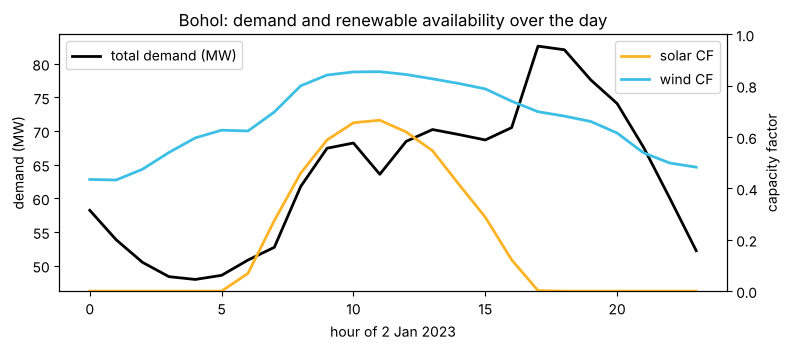

In [2]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(range(24), loads_t.sum(axis=1).values, "k-", lw=2, label="total demand (MW)")
ax2 = ax.twinx()
ax2.plot(range(24), gens_t["SOLAR_BOHOL"].values, color=COLORS["Solar"], lw=2, label="solar CF")
ax2.plot(range(24), gens_t["WIND_BOHOL"].values, color=COLORS["Wind"], lw=2, label="wind CF")
ax.set_xlabel("hour of 2 Jan 2023"); ax.set_ylabel("demand (MW)")
ax2.set_ylabel("capacity factor"); ax2.set_ylim(0, 1)
ax.legend(loc="upper left"); ax2.legend(loc="upper right")
ax.set_title("Bohol: demand and renewable availability over the day")
fig.tight_layout(); fig.savefig(FIG / "05_profiles.png", dpi=130); plt.show()

### 5.2 Build the time-dependent network

Two new modelling ideas:

- A **variable renewable** generator gets a `p_max_pu` time series: its output
  can be anything from 0 up to `p_nom * p_max_pu[t]` each hour (the solver may
  curtail it, but never exceed availability).
- We cap the submarine cable at 45 MW this day (a maintenance limit). That
  creates a real daily squeeze: midday the island has surplus renewable energy,
  the evening peak is tight. Perfect conditions to show what a battery does.

In [3]:
def bohol_day(battery_mw=0.0, solar_mw=60.0, wind_mw=45.0, cable_mw=45.0):
    n = pypsa.Network()
    n.set_snapshots(loads_t.index)              # 24 hourly snapshots
    for b in buses.itertuples():
        n.add("Bus", b.name, v_nom=b.v_nom, x=b.x, y=b.y)
    for c in carriers.itertuples():
        n.add("Carrier", c.name, co2_emissions=c.co2_emissions, color=c.color)
    for l in lines.itertuples():
        n.add("Line", l.name, bus0=l.bus0, bus1=l.bus1, r=l.r, x=l.x, s_nom=l.s_nom)
    # dispatchable fleet (diesel, hydro, capped grid import)
    for g in gens.itertuples():
        p_nom = cable_mw if g.carrier == "Grid" else g.p_nom
        n.add("Generator", g.name, bus=g.bus, carrier=g.carrier,
              p_nom=p_nom, marginal_cost=MC[g.carrier])
    # variable renewables, output capped hour by hour by the profile
    n.add("Generator", "SOLAR", bus="07TAPAL", carrier="Solar", p_nom=solar_mw,
          marginal_cost=MC["Solar"], p_max_pu=gens_t["SOLAR_BOHOL"].values)
    n.add("Generator", "WIND", bus="07UBAY", carrier="Wind", p_nom=wind_mw,
          marginal_cost=MC["Wind"], p_max_pu=gens_t["WIND_BOHOL"].values)
    # optional battery: power rating p_nom, energy = p_nom * max_hours
    if battery_mw:
        n.add("StorageUnit", "BATTERY", bus="07UBAY", carrier="Battery",
              p_nom=battery_mw, max_hours=4, marginal_cost=0.0,
              efficiency_store=1.0, efficiency_dispatch=0.95,
              cyclic_state_of_charge=True)   # end the day as it began
    for bus, col, name in [("07CORELLA", "07CORELLA_LOAD", "Load_Corella"),
                           ("07UBAY", "07UBAY_LOAD", "Load_Ubay")]:
        n.add("Load", name, bus=bus, p_set=loads_t[col].values)
    return n

OPT = dict(solver_name="highs", solver_options={"output_flag": False}, log_to_console=False)

def energy_by_carrier(n):
    return n.generators_t.p.T.groupby(n.generators.carrier).sum().T

### 5.3 Solve the day **without** a battery

Watch what happens at midday: solar and wind together exceed what the island can
use or export, so the solver is forced to **curtail** (spill) free renewable
energy. That spilled energy is the opportunity a battery will capture.

In [4]:
n0 = bohol_day(battery_mw=0.0)
n0.optimize(**OPT)

E0 = energy_by_carrier(n0).sum()
demand = n0.loads_t.p.sum().sum()
avail = (n0.generators[["p_nom"]].T[["SOLAR", "WIND"]].values
         * gens_t[["SOLAR_BOHOL", "WIND_BOHOL"]].values).sum()
used = energy_by_carrier(n0)[["Solar", "Wind"]].sum().sum()
print("Daily demand:", round(demand), "MWh")
print("\nEnergy by carrier (MWh):"); print(E0.round(0).to_string())
print(f"\nRenewable available {avail:.0f} MWh, used {used:.0f} MWh, "
      f"curtailed {avail - used:.0f} MWh")
print(f"Renewable share {100 * used / demand:.1f} % | cost {float(n0.objective):.0f}")

Daily demand: 1516 MWh

Energy by carrier (MWh):
carrier
Diesel      0.0
Grid      382.0
Hydro     238.0
Solar     283.0
Wind      614.0

Renewable available 1001 MWh, used 896 MWh, curtailed 105 MWh
Renewable share 59.1 % | cost 17289


### 5.4 Solve the day **with** a 20 MW / 4 h battery

A `StorageUnit` charges when energy is cheap and plentiful (midday surplus) and
discharges when it is dear (evening peak). `max_hours=4` means its energy store
is 20 MW x 4 h = 80 MWh. `cyclic_state_of_charge=True` forces it to end the day
at the same charge it started, so we are not secretly "borrowing" energy.

In [5]:
n1 = bohol_day(battery_mw=20.0)
n1.optimize(**OPT)

E1 = energy_by_carrier(n1).sum()
used1 = energy_by_carrier(n1)[["Solar", "Wind"]].sum().sum()
soc = n1.storage_units_t.state_of_charge["BATTERY"]
print("Energy by carrier with battery (MWh):"); print(E1.round(0).to_string())
print(f"\nRenewable used {used1:.0f} MWh (was {used:.0f}), "
      f"curtailed {avail - used1:.0f} MWh (was {avail - used:.0f})")
print(f"Renewable share {100 * used1 / demand:.1f} % | cost {float(n1.objective):.0f} "
      f"(was {float(n0.objective):.0f}, a {100*(1-n1.objective/n0.objective):.0f} % saving)")
print(f"Battery energy swing: {soc.min():.0f} to {soc.max():.0f} MWh")

Energy by carrier with battery (MWh):
carrier
Diesel      0.0
Grid      306.0
Hydro     238.0
Solar     283.0
Wind      694.0

Renewable used 976 MWh (was 896), curtailed 25 MWh (was 105)
Renewable share 64.4 % | cost 14169 (was 17289, a 18 % saving)
Battery energy swing: -0 to 80 MWh


### 5.5 Picture the day: generation stack and battery

The stack shows who supplies each hour; the black line is demand. The battery
panel below shows it **charging** (negative) at midday and **discharging**
(positive) in the evening - textbook load-shifting.

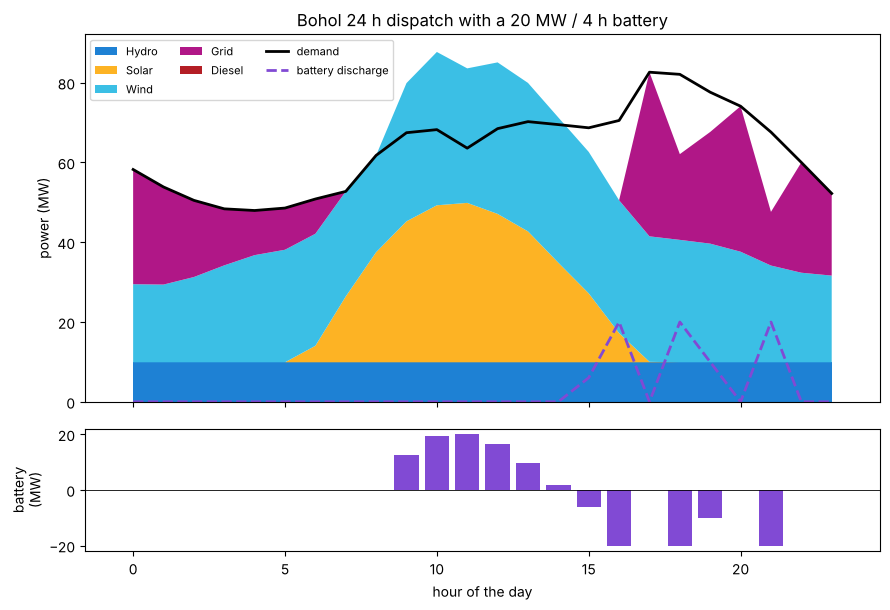

saved figures/05_dispatch_storage.png


In [6]:
hours = range(24)
order = ["Hydro", "Solar", "Wind", "Grid", "Diesel"]
stack = energy_by_carrier(n1).reindex(columns=order, fill_value=0.0)
batt_p = n1.storage_units_t.p["BATTERY"]

fig, (axA, axB) = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
axA.stackplot(hours, [stack[c].values for c in order],
              labels=order, colors=[COLORS[c] for c in order])
axA.plot(hours, n1.loads_t.p.sum(axis=1).values, "k-", lw=2, label="demand")
axA.plot(hours, batt_p.clip(lower=0).values, color=COLORS["Battery"], lw=2,
         ls="--", label="battery discharge")
axA.set_ylabel("power (MW)"); axA.legend(ncol=3, fontsize=8, loc="upper left")
axA.set_title("Bohol 24 h dispatch with a 20 MW / 4 h battery")

axB.bar(hours, (-batt_p).values, color=COLORS["Battery"],
        label="charge (+) / discharge (-)")
axB.axhline(0, color="k", lw=0.6)
axB.set_ylabel("battery\n(MW)"); axB.set_xlabel("hour of the day")
fig.tight_layout(); fig.savefig(FIG / "05_dispatch_storage.png", dpi=130); plt.show()
print("saved figures/05_dispatch_storage.png")

## Summary of Chapter 5

- `n.set_snapshots()` turns a one-shot model into a time series; renewables use
  a `p_max_pu` profile so their ceiling moves hour by hour.
- Without storage, the island must **curtail ~105 MWh** of free renewable energy
  at midday because it cannot use or export it.
- A 20 MW / 4 h `StorageUnit` charges on the midday surplus and discharges at the
  evening peak: **curtailment falls to ~25 MWh, cost drops ~18 %, and the
  renewable share rises** - with no extra fuel.
- Next chapter we add two policy-style constraints: a **CO2 cap** and a
  **congested line**.